# Project 2: Data Visualization with Matplotlib & Seaborn

## Analysis Questions

1. How are restaurant bills distributed?
2. Do tips differ by day?
3. Does a bigger bill mean a bigger tip?
4. Which numerical variables are correlated with each other?

## Objective

The objective of this project is to visualize restaurant billing and tipping patterns using Matplotlib and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = sns.load_dataset("tips")

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (244, 7)


In [6]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [8]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [9]:
df.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [10]:
sns.set_theme(
    style="whitegrid",
    palette="deep"
)

In [11]:
print(df.columns)

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')


**1. Histogram – Total Bill Distribution**

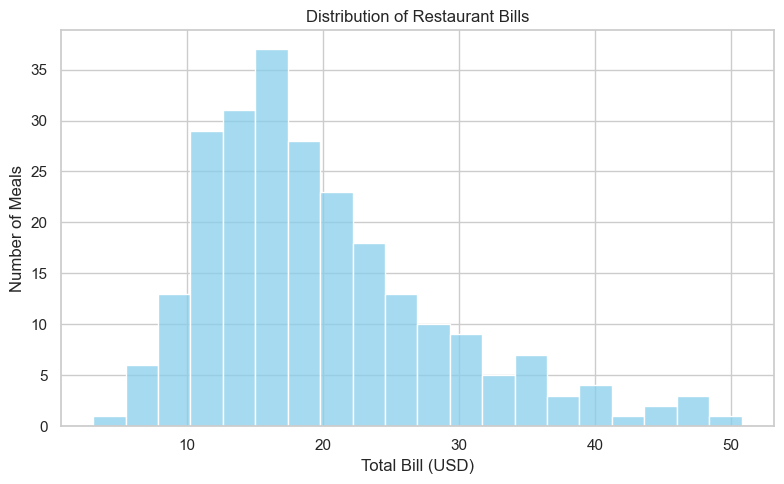

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    color="skyblue"
)

plt.title("Distribution of Restaurant Bills")
plt.xlabel("Total Bill (USD)")
plt.ylabel("Number of Meals")

plt.tight_layout()
plt.show()

**2.Box Plot – Tips Across Different Days**

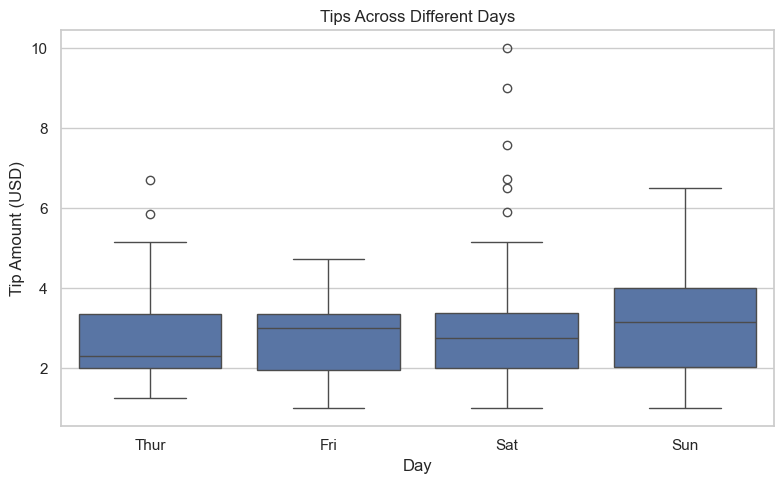

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="day", y="tip")

plt.title("Tips Across Different Days")
plt.xlabel("Day")
plt.ylabel("Tip Amount (USD)")

plt.tight_layout()
plt.show()

**3. Scatter Plot – Total Bill vs Tip**

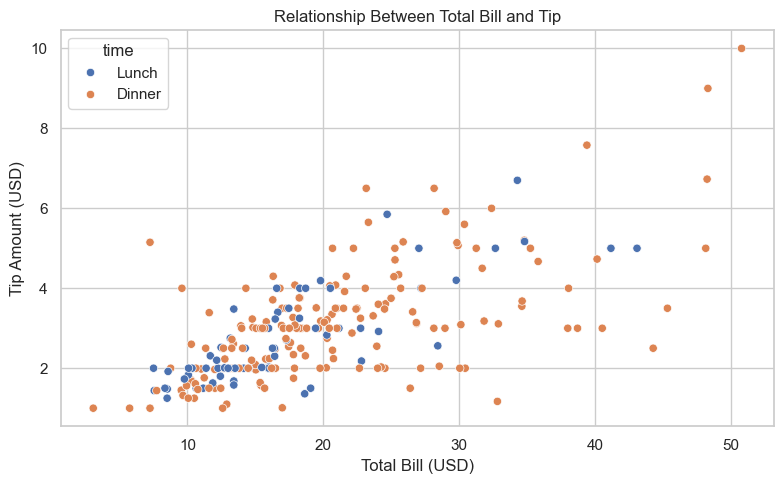

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="time"
)

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill (USD)")
plt.ylabel("Tip Amount (USD)")

plt.tight_layout()
plt.show()

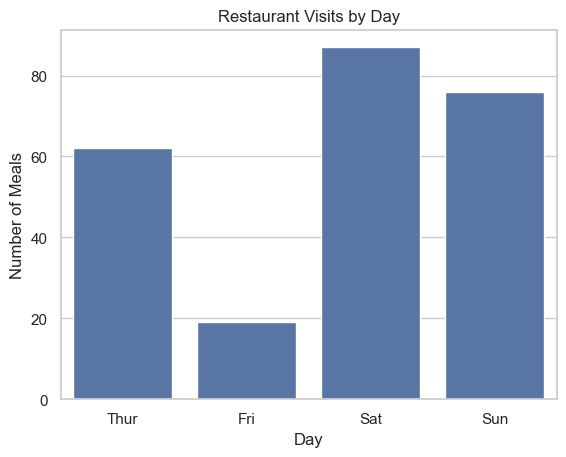

In [16]:
sns.set_palette("deep")

sns.countplot(data=df, x="day")

plt.title("Restaurant Visits by Day")
plt.xlabel("Day")
plt.ylabel("Number of Meals")

plt.show()

**4.Correlation Heatmap**

In [17]:
correlation = df.select_dtypes("number").corr()

print(correlation)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


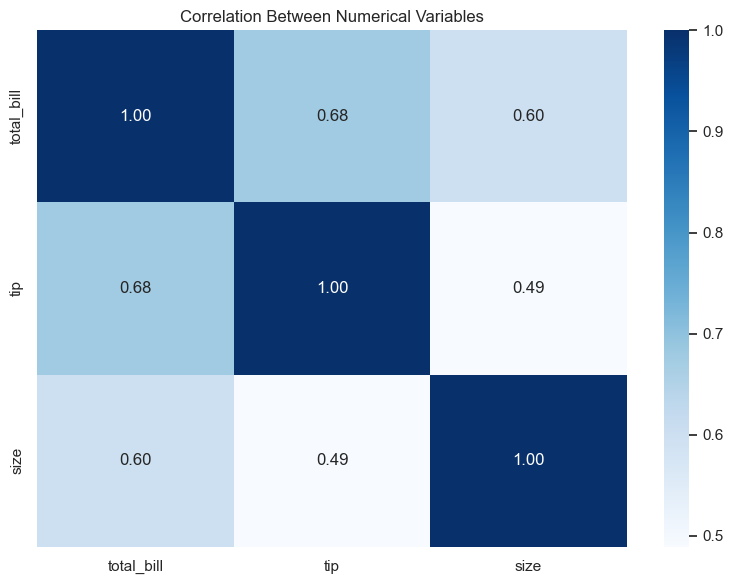

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.show()

In [19]:
corr_pairs = correlation.abs().unstack()

corr_pairs = corr_pairs[
    corr_pairs < 1
]

print(corr_pairs.sort_values(ascending=False).head(2))

total_bill  tip           0.675734
tip         total_bill    0.675734
dtype: float64


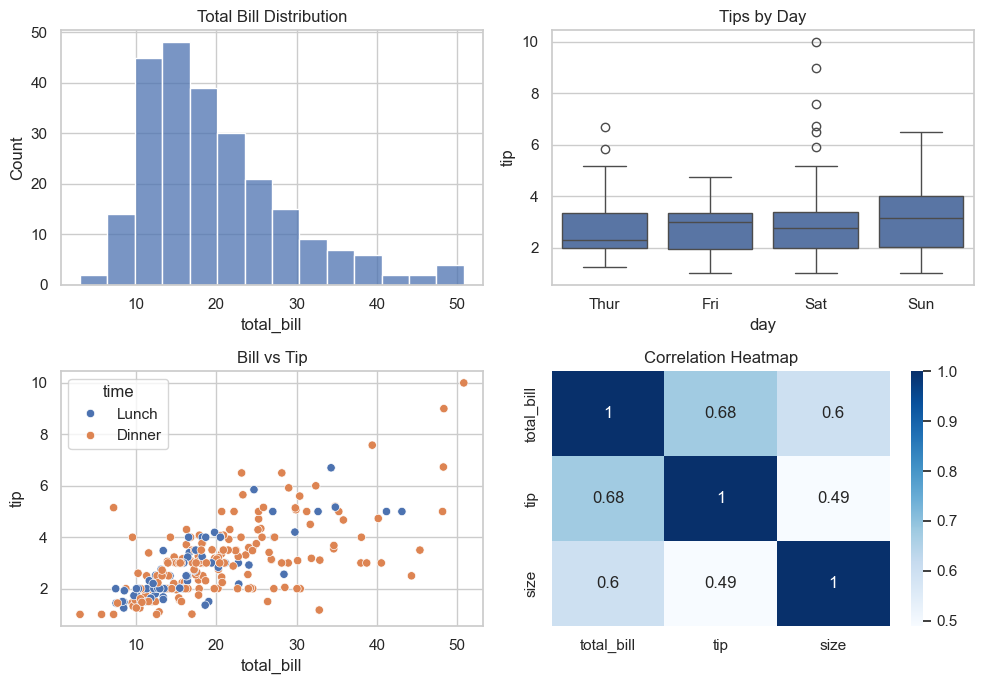

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# 1. Histogram
sns.histplot(df["total_bill"], ax=axes[0, 0])
axes[0, 0].set_title("Total Bill Distribution")

# 2. Box Plot
sns.boxplot(data=df, x="day", y="tip", ax=axes[0, 1])
axes[0, 1].set_title("Tips by Day")

# 3. Scatter Plot
sns.scatterplot(data=df, x="total_bill", y="tip",
                hue="time", ax=axes[1, 0])
axes[1, 0].set_title("Bill vs Tip")

# 4. Heatmap
sns.heatmap(df.select_dtypes("number").corr(),
            annot=True, cmap="Blues", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()

# Save dashboard
plt.savefig("tips_overview.png", dpi=150)

plt.show()


## Step 7: Key Findings and Observations

**1. Histogram – Total Bill Distribution**

Most restaurant bills are concentrated in the lower bill amounts.

**2. Box Plot – Tips by Day**

Tip amounts vary across different days.

**3. Scatter Plot – Bill vs Tip**

Customers generally give higher tips when the total bill is higher.

**4. Correlation Heatmap**

The heatmap shows the relationships between numerical columns in the dataset.